Dataset Loaded Successfully


,rownames,Gunnel,Time,Fromlow,Slope,Rw,Amphiso,Subst,Pool,Water,Cobble
0,1,0,786,190,10,0.1,0,3,0,0,0
1,2,0,794,182,10,0.0,0,3,0,0,0
2,3,0,798,178,20,0.0,0,1,0,0,0
3,4,0,800,176,70,0.3,0,1,0,1,0
4,5,0,804,172,40,0.3,0,1,0,1,0


Index(['rownames', 'Gunnel', 'Time', 'Fromlow', 'Slope', 'Rw', 'Amphiso',
       'Subst', 'Pool', 'Water', 'Cobble'],
      dtype='str')
rownames      int64
Gunnel        int64
Time          int64
Fromlow       int64
Slope         int64
Rw          float64
Amphiso       int64
Subst         int64
Pool          int64
Water         int64
Cobble        int64
dtype: object
Contingency Table:


Cobble,0,1
Water,,
0,659,123
1,629,181


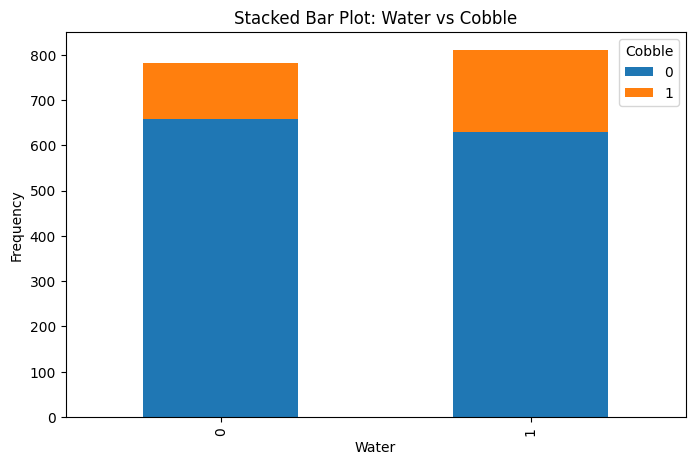

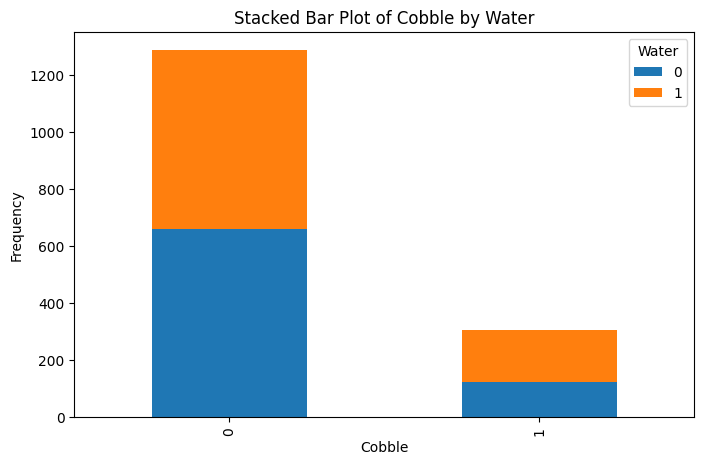

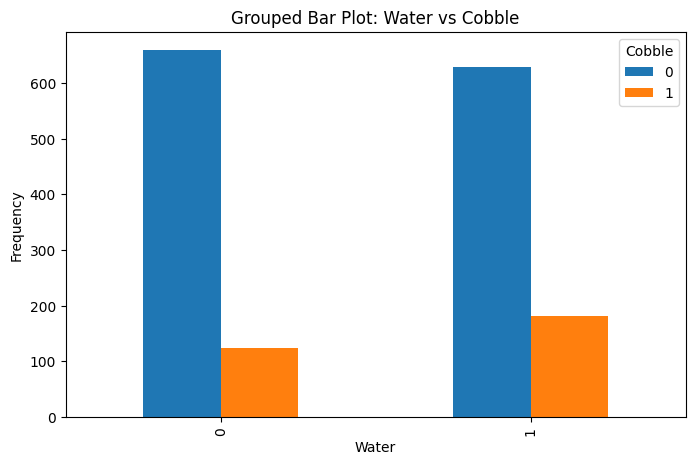

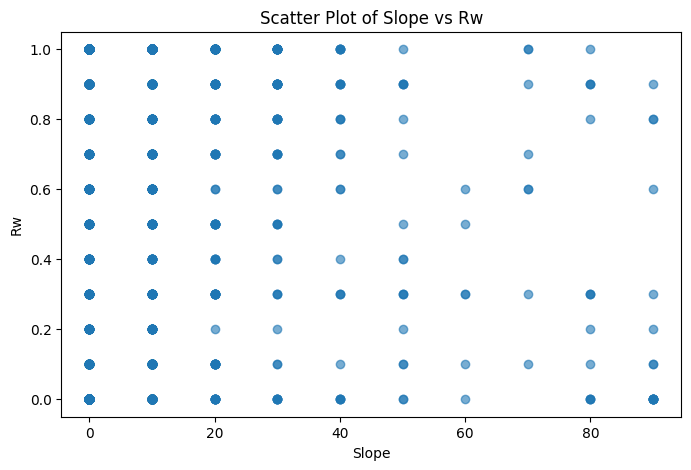

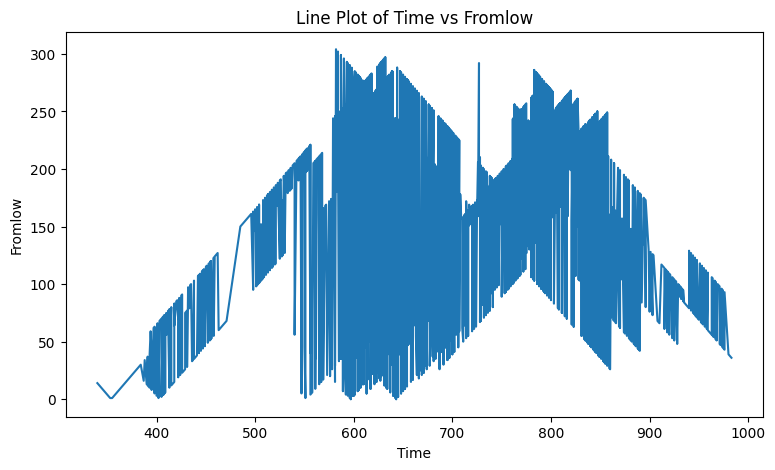

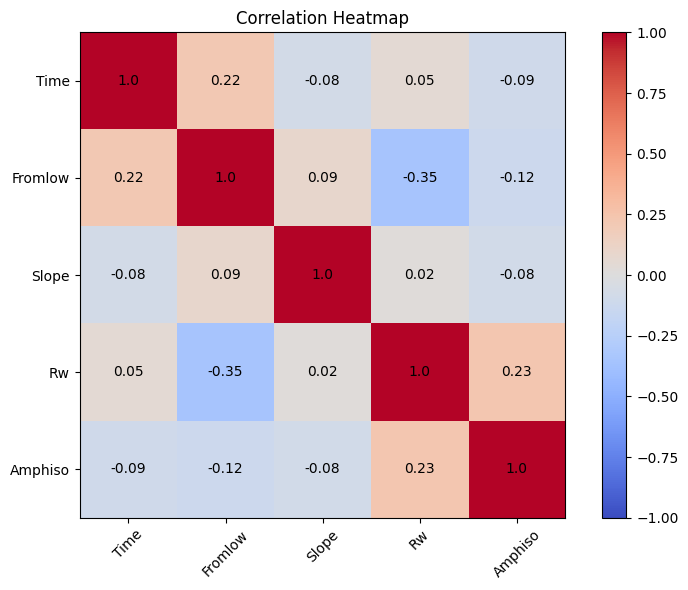

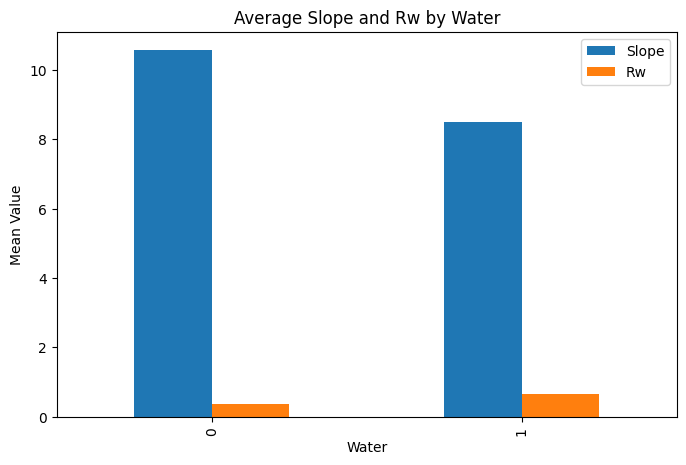

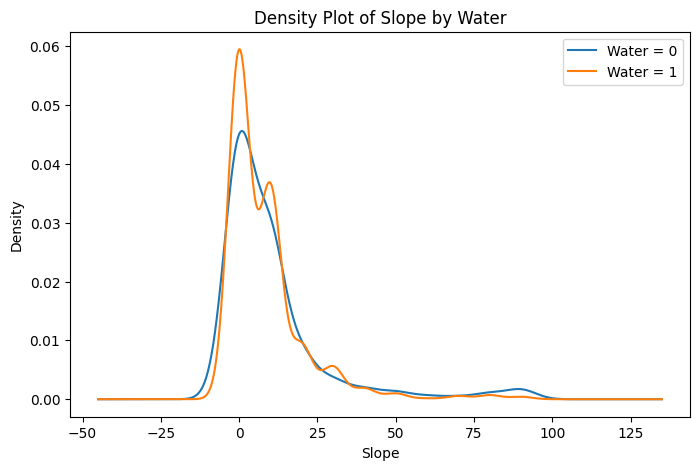

C:\Users\aksha\AppData\Local\Temp\ipykernel_17880\3147522024.py:200: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


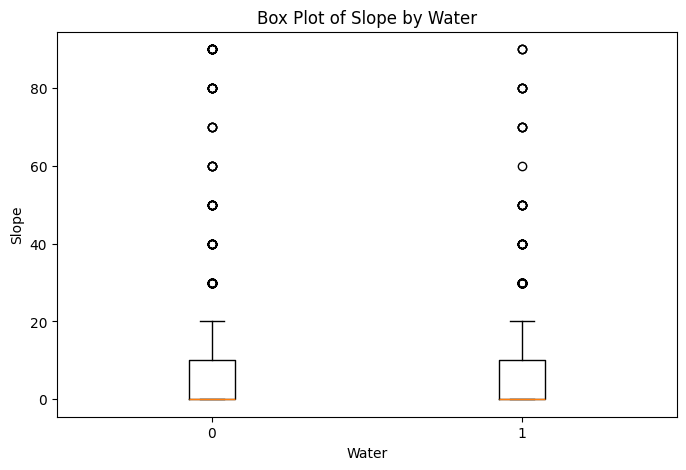

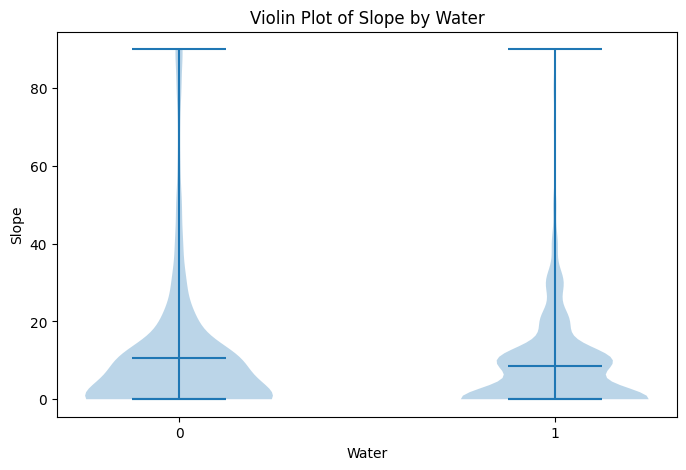

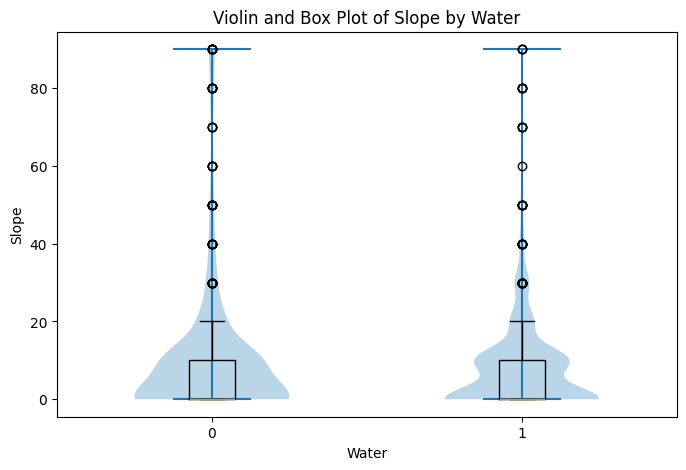

Correlation Matrix:


,Time,Fromlow,Slope,Rw,Amphiso
Time,1.000000,0.215593,-0.076922,0.047812,-0.094952
Fromlow,0.215593,1.000000,0.090586,-0.348612,-0.118838
Slope,-0.076922,0.090586,1.000000,0.019566,-0.078461
Rw,0.047812,-0.348612,0.019566,1.000000,0.230164
Amphiso,-0.094952,-0.118838,-0.078461,0.230164,1.000000


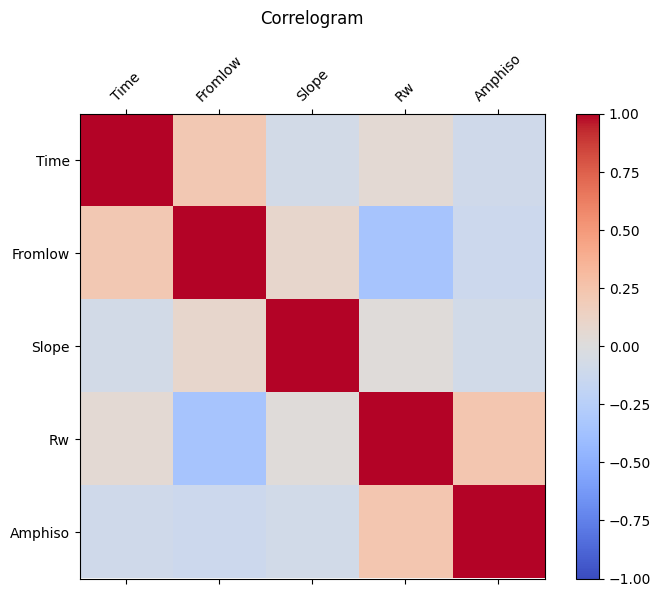

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ASSESSMENT 4
# BIVARIATE ANALYSIS

# 1. Load Dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Gunnels.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")
display(df.head())

print(df.columns)
print(df.dtypes)

# Treat selected coded variables as categorical
df["Water"] = df["Water"].astype(str)
df["Cobble"] = df["Cobble"].astype(str)
df["Pool"] = df["Pool"].astype(str)
df["Gunnel"] = df["Gunnel"].astype(str)

# 2. Contingency Table and Stacked Bar Plot
contingency = pd.crosstab(
    df["Water"],
    df["Cobble"]
)

print("Contingency Table:")
display(contingency)

contingency.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Stacked Bar Plot: Water vs Cobble")
plt.xlabel("Water")
plt.ylabel("Frequency")
plt.legend(title="Cobble")
plt.show()

# Alternative stacked bar representation
contingency.T.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Stacked Bar Plot of Cobble by Water")
plt.xlabel("Cobble")
plt.ylabel("Frequency")
plt.legend(title="Water")
plt.show()

# 3. Grouped / Side-by-Side Bar Plot
contingency.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Grouped Bar Plot: Water vs Cobble")
plt.xlabel("Water")
plt.ylabel("Frequency")
plt.legend(title="Cobble")
plt.show()

# 4. Scatter Plot
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Slope"],
    df["Rw"],
    alpha=0.6
)

plt.title("Scatter Plot of Slope vs Rw")
plt.xlabel("Slope")
plt.ylabel("Rw")
plt.show()

# 5. Line Plot
line_data = df.sort_values("Time")

plt.figure(figsize=(9, 5))

plt.plot(
    line_data["Time"],
    line_data["Fromlow"]
)

plt.title("Line Plot of Time vs Fromlow")
plt.xlabel("Time")
plt.ylabel("Fromlow")
plt.show()

# 6. Heatmap
numerical_variables = [
    "Time",
    "Fromlow",
    "Slope",
    "Rw",
    "Amphiso"
]

correlation = df[
    numerical_variables
].corr()

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

for i in range(len(correlation)):
    for j in range(len(correlation)):
        plt.text(
            j,
            i,
            round(correlation.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 7. Bar Chart Comparing Two Variables
bar_data = df.groupby(
    "Water"
)[["Slope", "Rw"]].mean()

bar_data.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Slope and Rw by Water")
plt.xlabel("Water")
plt.ylabel("Mean Value")
plt.show()

# 8. Density Plot
plt.figure(figsize=(8, 5))

for group in df["Water"].unique():

    data = df[
        df["Water"] == group
    ]["Slope"].dropna()

    if data.nunique() > 1:
        data.plot(
            kind="density",
            label=f"Water = {group}"
        )

plt.title("Density Plot of Slope by Water")
plt.xlabel("Slope")
plt.legend()
plt.show()

# 9. Box Plot
groups = []

labels = []

for group in sorted(df["Water"].unique()):

    values = df[
        df["Water"] == group
    ]["Slope"].dropna()

    groups.append(values)
    labels.append(group)

plt.figure(figsize=(8, 5))

plt.boxplot(
    groups,
    labels=labels
)

plt.title("Box Plot of Slope by Water")
plt.xlabel("Water")
plt.ylabel("Slope")
plt.show()

# 10. Violin Plot
plt.figure(figsize=(8, 5))

plt.violinplot(
    groups,
    showmeans=True,
    showmedians=True
)

plt.xticks(
    range(1, len(labels) + 1),
    labels
)

plt.title("Violin Plot of Slope by Water")
plt.xlabel("Water")
plt.ylabel("Slope")
plt.show()

# 11. Combined Violin Plot and Box Plot
plt.figure(figsize=(8, 5))

plt.violinplot(
    groups,
    showmeans=False,
    showmedians=False
)

plt.boxplot(
    groups,
    widths=0.15
)

plt.xticks(
    range(1, len(labels) + 1),
    labels
)

plt.title("Violin and Box Plot of Slope by Water")
plt.xlabel("Water")
plt.ylabel("Slope")
plt.show()

# 12. Correlation Matrix and Correlogram
numerical_variables = [
    "Time",
    "Fromlow",
    "Slope",
    "Rw",
    "Amphiso"
]

corr_matrix = df[
    numerical_variables
].corr()

print("Correlation Matrix:")
display(corr_matrix)

plt.figure(figsize=(8, 6))

plt.matshow(
    corr_matrix,
    fignum=1,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar()

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Correlogram", pad=20)

plt.show()